In [1]:
import os
os.getcwd()

'/home/rohit13595/rl-projects/pro3-multifeedbackRLHF/RL-withMultiHumanFeedback'

✅ Successfully loaded and plotted all 5 seeds.

🖼️ Plot saved to: multi_seed_sac_Hopper-v5_performance.png


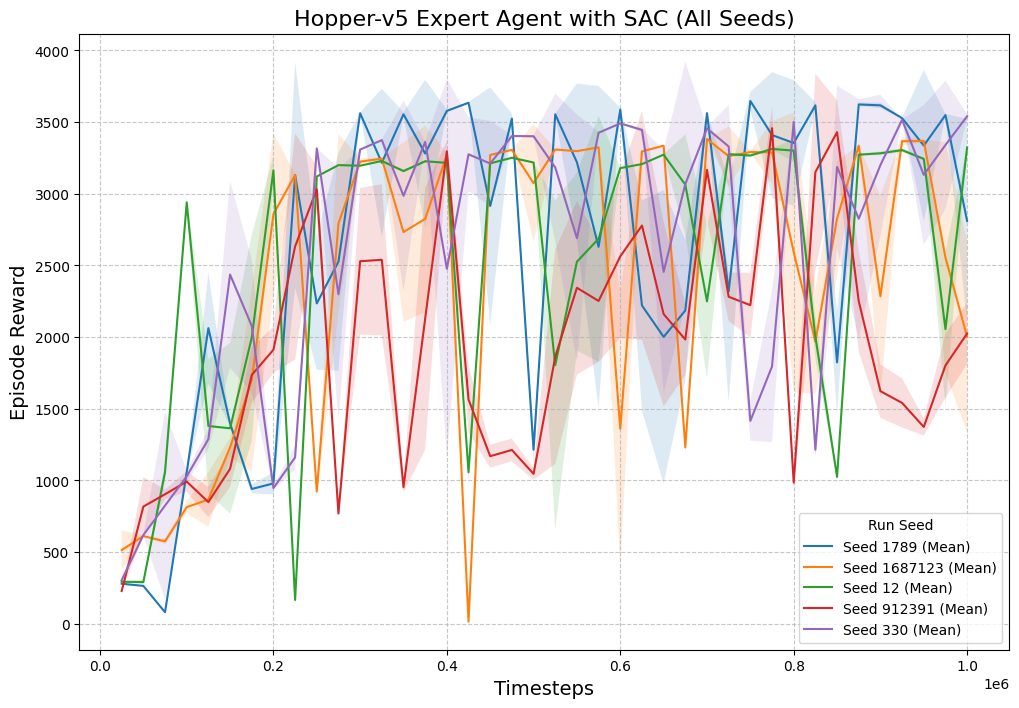

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION: UPDATE THESE VALUES ---
# 🚨 IMPORTANT: Change 'Hopper-v5' and 'sac' if your environment or algorithm are different.
ALGORITHM = "sac"
ENVIRONMENT = "Hopper-v5"
BASE_PATH = "./gt_agents" 

# The seeds you want to plot
GT_SEEDS = [1789, 1687123, 12, 912391, 330]
# --------------------------------------------

def plot_learning_curves(seeds: list, algorithm: str, environment: str, base_path: str):
    """
    Loads evaluations.npz data for multiple seeds, calculates mean rewards, 
    and plots them on a single figure.
    """
    
    plt.figure(figsize=(12, 8))
    
    all_data_found = True

    for seed in seeds:
        # Construct the expected path for the evaluations.npz file
        # Path: gt_agents/sac/Hopper-v5_12/evaluations.npz
        run_dir = f"{environment}_{seed}"
        npz_path = os.path.join(base_path, algorithm, run_dir, "evaluations.npz")
        
        if not os.path.isfile(npz_path):
            print(f"⚠️ Warning: File not found for seed {seed} at path: {npz_path}")
            all_data_found = False
            continue

        try:
            data = np.load(npz_path)
            timesteps = data['timesteps']
            results = data['results'] 
            
            # Calculate the mean and standard deviation of rewards across all evaluation episodes
            mean_rewards = np.mean(results, axis=1)
            std_rewards = np.std(results, axis=1)

            # Plot the mean reward curve
            plt.plot(timesteps, mean_rewards, label=f"Seed {seed} (Mean)")
            
            # Plot the shaded area for standard deviation (optional, but good practice)
            plt.fill_between(
                timesteps, 
                mean_rewards - std_rewards, 
                mean_rewards + std_rewards, 
                alpha=0.15 # Light transparency
            )

        except Exception as e:
            print(f"❌ Error loading or processing data for seed {seed}: {e}")
            all_data_found = False

    if all_data_found:
        print(f"✅ Successfully loaded and plotted all {len(seeds)} seeds.")
    
    # --- Plotting Final Touches ---
    plt.title(f"{environment} Expert Agent with {algorithm.upper()} (All Seeds)", fontsize=16)
    plt.xlabel("Timesteps", fontsize=14)
    plt.ylabel("Episode Reward", fontsize=14)
    plt.legend(title="Run Seed")
    plt.grid(True, linestyle='--', alpha=0.7)
    
    # Save the figure
    plot_filename = f"multi_seed_{algorithm}_{environment}_performance.png"
    plt.savefig(plot_filename)
    print(f"\n🖼️ Plot saved to: {plot_filename}")

# Execute the plotting function
plot_learning_curves(GT_SEEDS, ALGORITHM, ENVIRONMENT, BASE_PATH)

Preparing to plot a 3x2 grid (one subplot per feedback type)...
⚠️ Warning: File not found for evaluative (Seed 12).
⚠️ Warning: File not found for evaluative (Seed 912391).
⚠️ Warning: File not found for evaluative (Seed 330).
⚠️ Warning: File not found for comparative (Seed 12).
⚠️ Warning: File not found for comparative (Seed 912391).
⚠️ Warning: File not found for comparative (Seed 330).
⚠️ Warning: File not found for demonstrative (Seed 12).
⚠️ Warning: File not found for demonstrative (Seed 912391).
⚠️ Warning: File not found for demonstrative (Seed 330).
⚠️ Warning: File not found for corrective (Seed 1687123).
⚠️ Warning: File not found for corrective (Seed 12).
⚠️ Warning: File not found for corrective (Seed 912391).
⚠️ Warning: File not found for corrective (Seed 330).
⚠️ Warning: File not found for descriptive (Seed 1687123).
⚠️ Warning: File not found for descriptive (Seed 12).
⚠️ Warning: File not found for descriptive (Seed 912391).
⚠️ Warning: File not found for descript

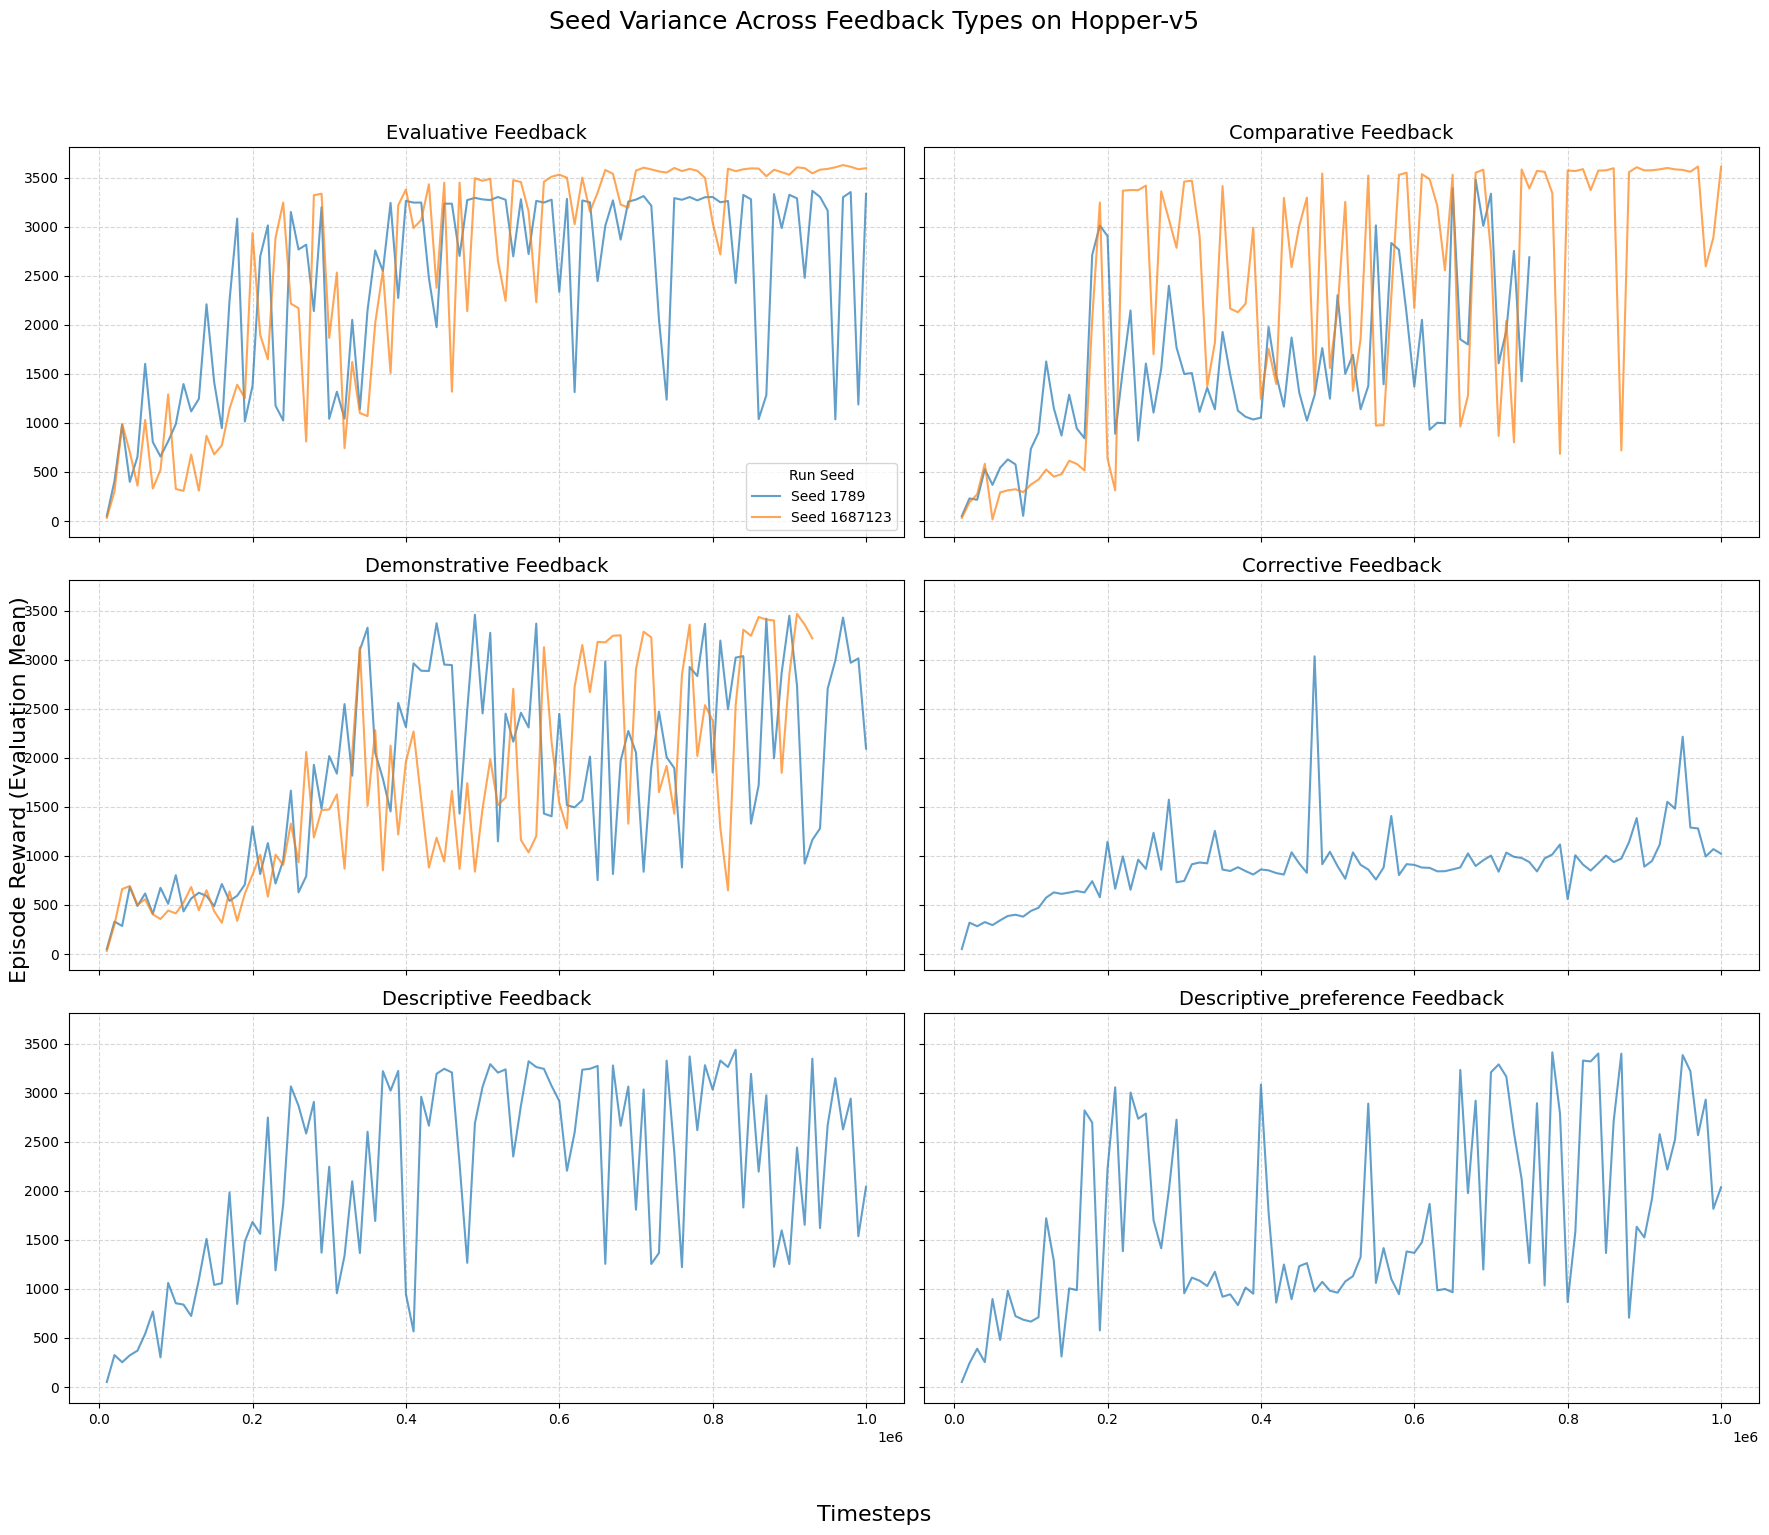

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION: UPDATE THESE VALUES ---
ALGORITHM = "sac"
ENVIRONMENT = "Hopper-v5"

# Base path needs to point to the directory containing the 'agents' folder
BASE_PROJECT_PATH = "/home/rohit13595/rl-projects/pro3-multifeedbackRLHF/RL-withMultiHumanFeedback"
AGENTS_DIR = "agents" 

# The seeds you want to plot (5 lines per subplot)
GT_SEEDS = [1789, 1687123, 12, 912391, 330]

# All feedback types (6 subplots will be generated in a 3x2 grid)
FEEDBACK_TYPES = [
    "evaluative", 
    "comparative", 
    "demonstrative", 
    "corrective", 
    "descriptive", 
    "descriptive_preference"
]
# --------------------------------------------

def plot_feedback_grid(seeds: list, feedback_types: list, algorithm: str, environment: str, base_path: str, agents_dir: str):
    """
    Generates a single figure with a grid of subplots (one per feedback type), 
    showing all seed runs within each subplot.
    """
    
    # 3 rows, 2 columns for the 6 feedback types
    N_ROWS = 3
    N_COLS = 2
    
    # Create the figure and the grid of Axes objects (subplots)
    # Share the X-axis and Y-axis scale across all subplots for better comparison
    fig, axs = plt.subplots(N_ROWS, N_COLS, figsize=(18, 15), sharex=True, sharey=True)
    
    # Flatten the 2D array of Axes into a 1D array for easier iteration
    axs_flat = axs.flatten()
    
    print(f"Preparing to plot a {N_ROWS}x{N_COLS} grid (one subplot per feedback type)...")

    for i, feedback_type in enumerate(feedback_types):
        ax = axs_flat[i] # Get the current subplot axis
        
        # --- Find Global Y-axis Range (Optional, but recommended for clean shared axes) ---
        # If you need to enforce a specific y-range for all plots, set it here.
        # ax.set_ylim(0, 1000) 

        for seed in seeds:
            # --- 1. Construct Path ---
            outer_dir = f"RL_{algorithm}_{environment}_{seed}_{feedback_type}_{seed}"
            inner_path = os.path.join(algorithm, f"{environment}_{seed}", "evaluations.npz")
            npz_path = os.path.join(base_path, agents_dir, outer_dir, inner_path)

            if not os.path.isfile(npz_path):
                print(f"⚠️ Warning: File not found for {feedback_type} (Seed {seed}).")
                continue

            try:
                # --- 2. Load and Process Data ---
                data = np.load(npz_path)
                timesteps = data['timesteps']
                results = data['results']
                mean_rewards_run = np.mean(results, axis=1)

                # --- 3. Plot Individual Seed Curve ---
                ax.plot(timesteps, mean_rewards_run, 
                        label=f"Seed {seed}", 
                        alpha=0.7)

            except Exception as e:
                print(f"❌ Error loading data for {feedback_type} (Seed {seed}): {e}")
                continue
        
        # --- 4. Subplot Final Touches ---
        ax.set_title(f"{feedback_type.capitalize()} Feedback", fontsize=14)
        ax.grid(True, linestyle='--', alpha=0.5)
        
        # Only add the legend to the first subplot to avoid clutter
        if i == 0:
            ax.legend(title="Run Seed", loc='lower right', fontsize=10)


    # --- 5. Figure Final Touches ---
    # Set a common X and Y label for the whole figure
    fig.supxlabel("Timesteps", fontsize=16)
    fig.supylabel("Episode Reward (Evaluation Mean)", fontsize=16)
    
    # Set the overall title
    fig.suptitle(f"Seed Variance Across Feedback Types on {environment}", fontsize=18, y=1.02)
    
    # Adjust spacing between plots and the edge of the figure
    plt.tight_layout(rect=[0, 0.03, 1, 0.98]) 
    
    # Save the figure
    plot_filename = f"grid_plot_{algorithm}_{environment}_variance.png"
    plt.savefig(plot_filename)
    print(f"\n🖼️ Plot saved to: {plot_filename}")


# Execute the plotting function
plot_feedback_grid(GT_SEEDS, FEEDBACK_TYPES, ALGORITHM, ENVIRONMENT, BASE_PROJECT_PATH, AGENTS_DIR)

Preparing to plot a 3x2 grid (one subplot per seed)...
⚠️ Warning: File not found for Seed 1687123 / corrective.
⚠️ Warning: File not found for Seed 1687123 / descriptive.
⚠️ Warning: File not found for Seed 1687123 / descriptive_preference.
⚠️ Warning: File not found for Seed 12 / evaluative.
⚠️ Warning: File not found for Seed 12 / comparative.
⚠️ Warning: File not found for Seed 12 / demonstrative.
⚠️ Warning: File not found for Seed 12 / corrective.
⚠️ Warning: File not found for Seed 12 / descriptive.
⚠️ Warning: File not found for Seed 12 / descriptive_preference.
⚠️ Warning: File not found for Seed 912391 / evaluative.
⚠️ Warning: File not found for Seed 912391 / comparative.
⚠️ Warning: File not found for Seed 912391 / demonstrative.
⚠️ Warning: File not found for Seed 912391 / corrective.
⚠️ Warning: File not found for Seed 912391 / descriptive.
⚠️ Warning: File not found for Seed 912391 / descriptive_preference.
⚠️ Warning: File not found for Seed 330 / evaluative.
⚠️ Warning

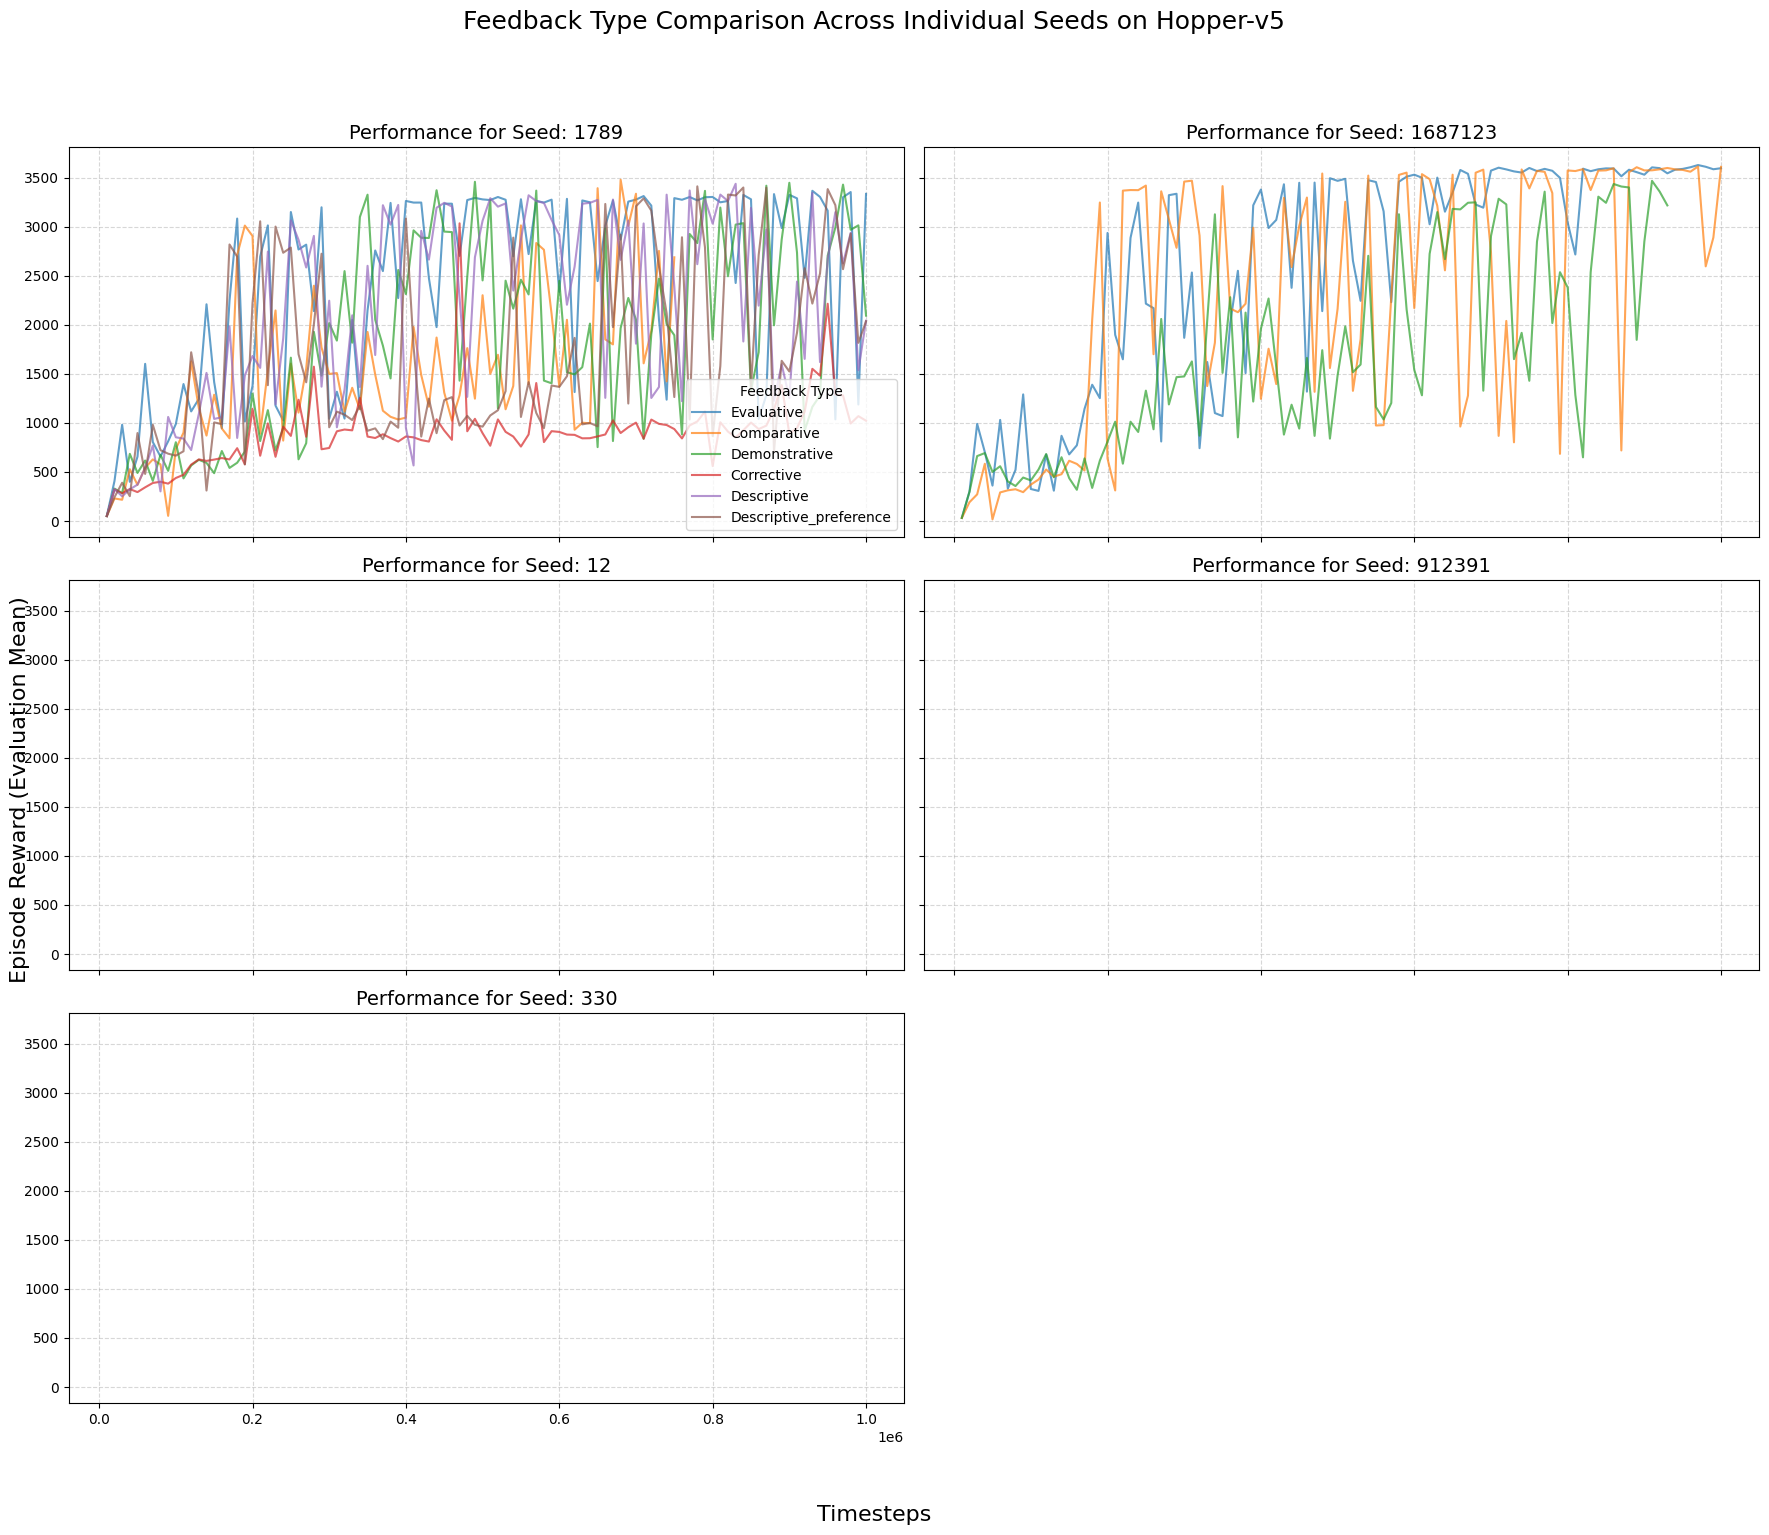

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION: UPDATE THESE VALUES ---
ALGORITHM = "sac"
ENVIRONMENT = "Hopper-v5"

# Base path needs to point to the directory containing the 'agents' folder
BASE_PROJECT_PATH = "/home/rohit13595/rl-projects/pro3-multifeedbackRLHF/RL-withMultiHumanFeedback"
AGENTS_DIR = "agents" 

# The seeds you want to plot (5 total)
GT_SEEDS = [1789, 1687123, 12, 912391, 330]

# All feedback types (6 lines per subplot)
FEEDBACK_TYPES = [
    "evaluative", 
    "comparative", 
    "demonstrative", 
    "corrective", 
    "descriptive", 
    "descriptive_preference"
]
# --------------------------------------------

def plot_per_seed_grid(seeds: list, feedback_types: list, algorithm: str, environment: str, base_path: str, agents_dir: str):
    """
    Generates a single figure with a grid of subplots (one per seed), 
    showing all feedback types within each subplot.
    """
    
    # We use a 3x2 grid (6 total slots) for 5 seeds + 1 empty space
    N_ROWS = 3
    N_COLS = 2
    
    fig, axs = plt.subplots(N_ROWS, N_COLS, figsize=(18, 15), sharex=True, sharey=True)
    axs_flat = axs.flatten()
    
    print(f"Preparing to plot a {N_ROWS}x{N_COLS} grid (one subplot per seed)...")

    # --- Outer Loop: Iterate through each SEED to create a Subplot ---
    for i, seed in enumerate(seeds):
        ax = axs_flat[i] # Get the current subplot axis
        
        # --- Inner Loop: Iterate through each FEEDBACK TYPE to draw a line ---
        for feedback_type in feedback_types:
            # --- 1. Construct Path ---
            outer_dir = f"RL_{algorithm}_{environment}_{seed}_{feedback_type}_{seed}"
            inner_path = os.path.join(algorithm, f"{environment}_{seed}", "evaluations.npz")
            npz_path = os.path.join(base_path, agents_dir, outer_dir, inner_path)

            if not os.path.isfile(npz_path):
                print(f"⚠️ Warning: File not found for Seed {seed} / {feedback_type}.")
                continue

            try:
                # --- 2. Load and Plot Data ---
                data = np.load(npz_path)
                timesteps = data['timesteps']
                results = data['results']
                mean_rewards_run = np.mean(results, axis=1)

                ax.plot(timesteps, mean_rewards_run, 
                        label=f"{feedback_type.capitalize()}", 
                        alpha=0.7)

            except Exception as e:
                print(f"❌ Error loading data for Seed {seed} / {feedback_type}: {e}")
                continue
        
        # --- 3. Subplot Final Touches ---
        ax.set_title(f"Performance for Seed: {seed}", fontsize=14)
        ax.grid(True, linestyle='--', alpha=0.5)
        
        # Add legend to the first plot only
        if i == 0:
            ax.legend(title="Feedback Type", loc='lower right', fontsize=10)

    # --- 4. Clean up the unused subplot (the 6th slot) ---
    if len(seeds) < len(axs_flat):
        for i in range(len(seeds), len(axs_flat)):
            fig.delaxes(axs_flat[i])


    # --- 5. Figure Final Touches ---
    fig.supxlabel("Timesteps", fontsize=16)
    fig.supylabel("Episode Reward (Evaluation Mean)", fontsize=16)
    fig.suptitle(f"Feedback Type Comparison Across Individual Seeds on {environment}", fontsize=18, y=1.02)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    
    plot_filename = f"grid_plot_per_seed_{algorithm}_{environment}.png"
    plt.savefig(plot_filename)
    print(f"\n🖼️ Plot saved to: {plot_filename}")


# Execute the plotting function
plot_per_seed_grid(GT_SEEDS, FEEDBACK_TYPES, ALGORITHM, ENVIRONMENT, BASE_PROJECT_PATH, AGENTS_DIR)

Preparing to plot a 3x2 grid (one ensemble run per seed)...
⚠️ Warning: Ensemble file not found for Seed 912391 at: /home/rohit13595/rl-projects/pro3-multifeedbackRLHF/RL-withMultiHumanFeedback/ensemble_agents/ENSEMBLE_RL_sac_Hopper-v5_912391_912391/sac/Hopper-v5_912391/evaluations.npz
⚠️ Warning: Ensemble file not found for Seed 330 at: /home/rohit13595/rl-projects/pro3-multifeedbackRLHF/RL-withMultiHumanFeedback/ensemble_agents/ENSEMBLE_RL_sac_Hopper-v5_330_330/sac/Hopper-v5_330/evaluations.npz

🖼️ Plot successfully saved to: grid_plot_ensemble_per_seed_sac_Hopper-v5.png


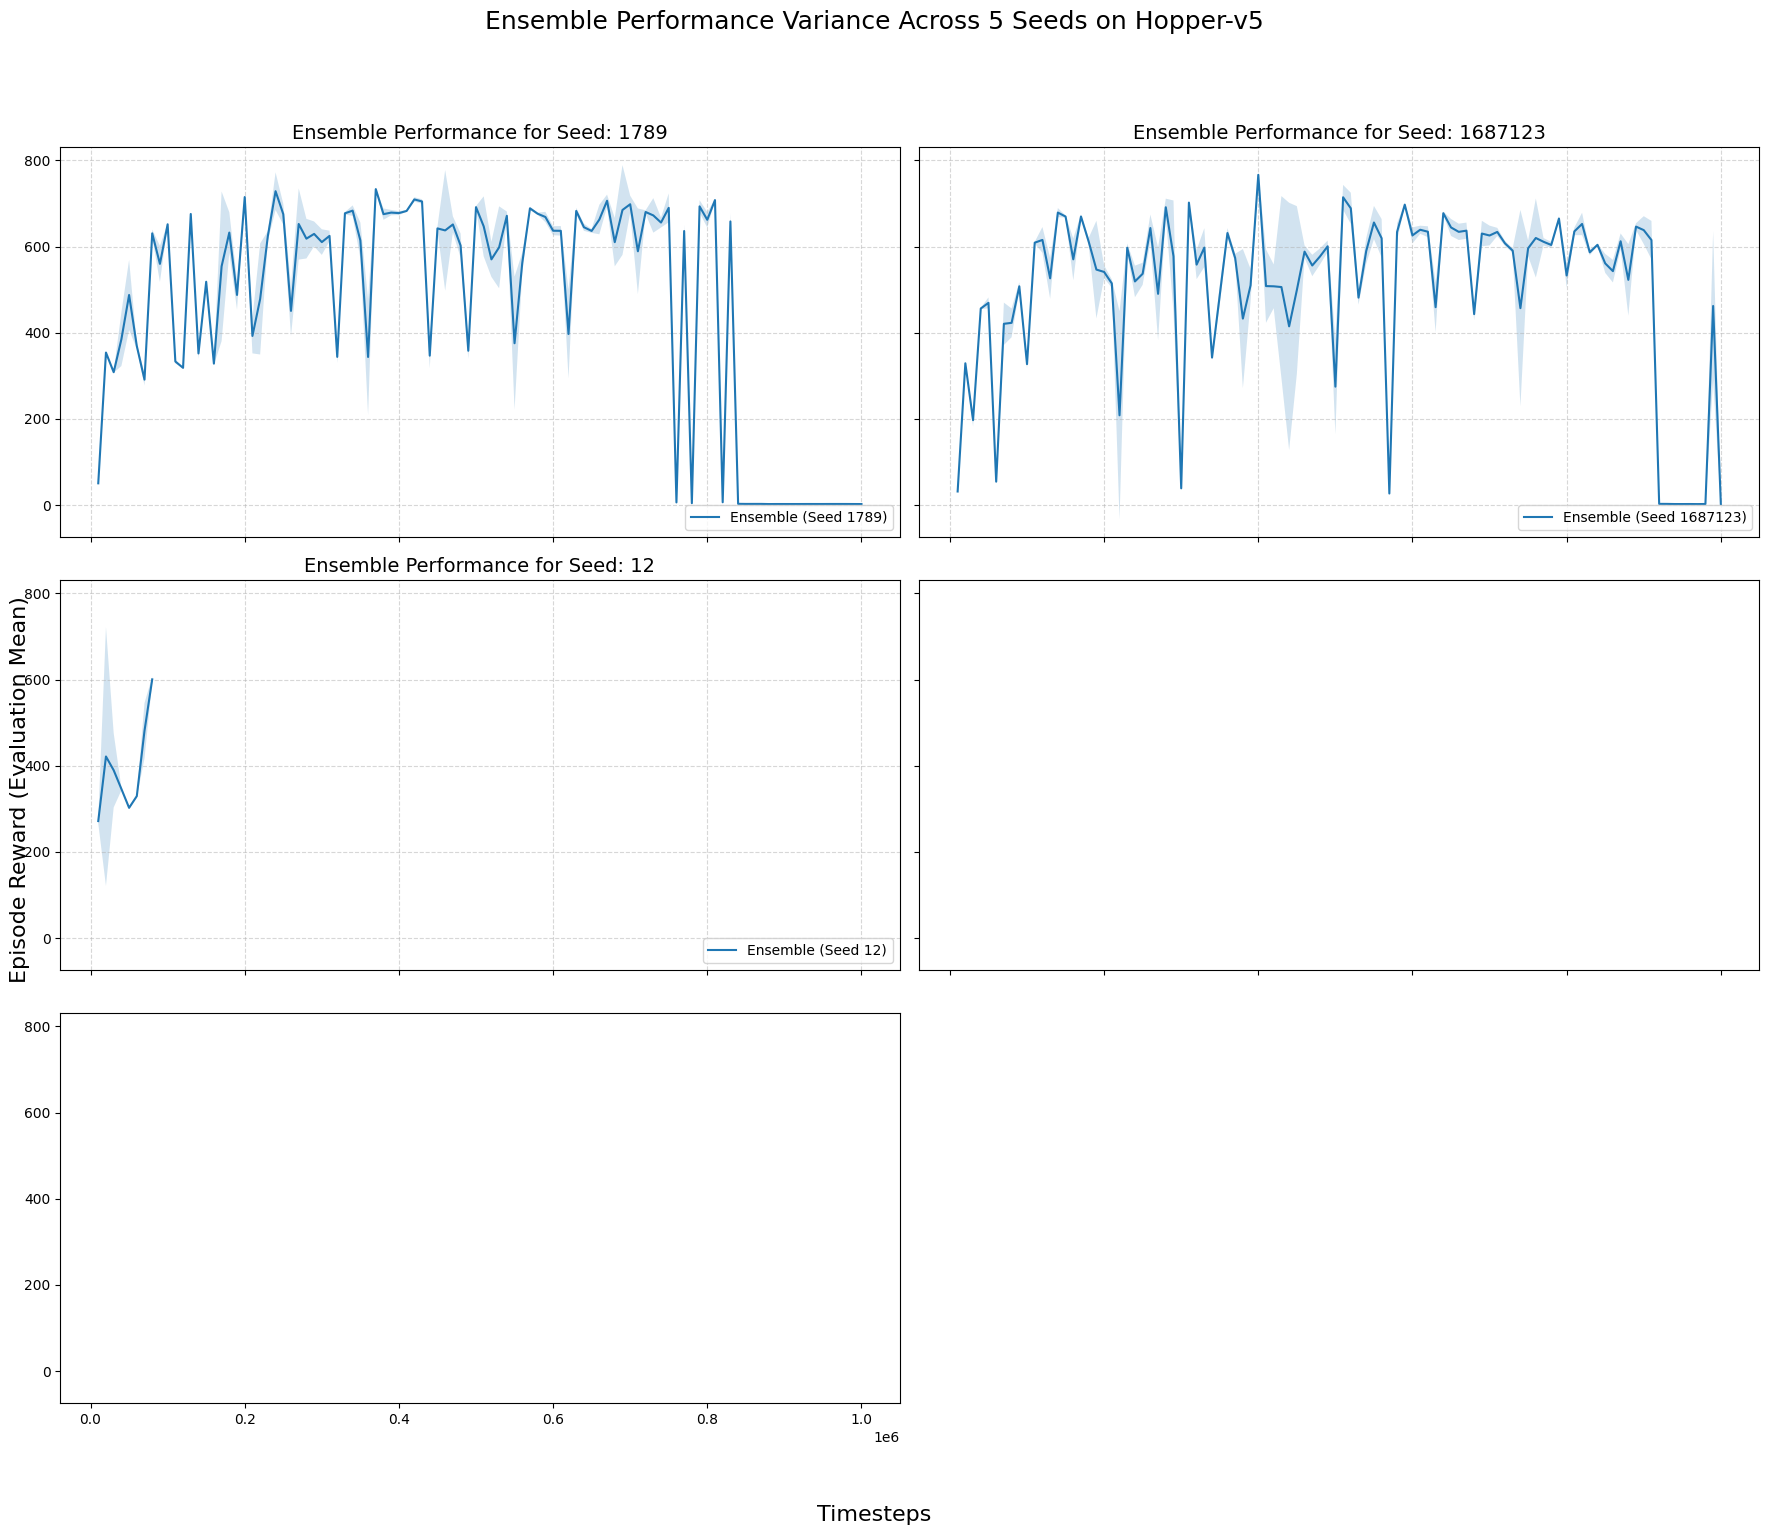

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION: UPDATE THESE VALUES ---
ALGORITHM = "sac"
ENVIRONMENT = "Hopper-v5"

# Base path needs to point to the directory containing the 'ensemble_agents' folder
BASE_PROJECT_PATH = "/home/rohit13595/rl-projects/pro3-multifeedbackRLHF/RL-withMultiHumanFeedback"
AGENTS_DIR = "ensemble_agents" 

# The seeds you want to plot (5 total)
GT_SEEDS = [1789, 1687123, 12, 912391, 330]
# --------------------------------------------

def plot_ensemble_per_seed_grid(seeds: list, algorithm: str, environment: str, base_path: str, agents_dir: str):
    """
    Generates a single figure with a grid of subplots (one per seed), 
    showing the ensemble agent's performance for that seed.
    """
    
    # We use a 3x2 grid (6 total slots) for 5 seeds + 1 empty space
    N_ROWS = 3
    N_COLS = 2
    
    # Share the X-axis and Y-axis scale across all subplots for comparison
    fig, axs = plt.subplots(N_ROWS, N_COLS, figsize=(18, 15), sharex=True, sharey=True)
    axs_flat = axs.flatten()
    
    print(f"Preparing to plot a {N_ROWS}x{N_COLS} grid (one ensemble run per seed)...")

    # --- Loop: Iterate through each SEED to create a Subplot ---
    for i, seed in enumerate(seeds):
        ax = axs_flat[i] # Get the current subplot axis
        
        # --- 1. Construct Path ---
        # Example path structure: /ensemble_agents/ENSEMBLE_RL_sac_Hopper-v5_12_12/sac/Hopper-v5_12/evaluations.npz
        outer_dir = f"ENSEMBLE_RL_{algorithm}_{environment}_{seed}_{seed}"
        inner_path = os.path.join(algorithm, f"{environment}_{seed}", "evaluations.npz")
        npz_path = os.path.join(base_path, agents_dir, outer_dir, inner_path)

        if not os.path.isfile(npz_path):
            print(f"⚠️ Warning: Ensemble file not found for Seed {seed} at: {npz_path}")
            continue

        try:
            # --- 2. Load and Plot Data ---
            data = np.load(npz_path)
            timesteps = data['timesteps']
            results = data['results']
            
            # Calculate mean and standard deviation of rewards for this single ensemble run
            mean_rewards = np.mean(results, axis=1)
            std_rewards = np.std(results, axis=1)

            # Plot the mean reward curve
            ax.plot(timesteps, mean_rewards, label=f"Ensemble (Seed {seed})")
            
            # Plot the shaded area for standard deviation (optional)
            ax.fill_between(
                timesteps, 
                mean_rewards - std_rewards, 
                mean_rewards + std_rewards, 
                alpha=0.2 
            )

        except Exception as e:
            print(f"❌ Error loading data for Ensemble Seed {seed}: {e}")
            continue
        
        # --- 3. Subplot Final Touches ---
        ax.set_title(f"Ensemble Performance for Seed: {seed}", fontsize=14)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(loc='lower right', fontsize=10) # Add legend to each subplot

    # --- 4. Clean up the unused subplot (the 6th slot) ---
    if len(seeds) < len(axs_flat):
        for i in range(len(seeds), len(axs_flat)):
            fig.delaxes(axs_flat[i])


    # --- 5. Figure Final Touches ---
    fig.supxlabel("Timesteps", fontsize=16)
    fig.supylabel("Episode Reward (Evaluation Mean)", fontsize=16)
    fig.suptitle(f"Ensemble Performance Variance Across {len(seeds)} Seeds on {environment}", fontsize=18, y=1.02)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    
    plot_filename = f"grid_plot_ensemble_per_seed_{algorithm}_{environment}.png"
    plt.savefig(plot_filename)
    print(f"\n🖼️ Plot successfully saved to: {plot_filename}")


# Execute the plotting function
plot_ensemble_per_seed_grid(GT_SEEDS, ALGORITHM, ENVIRONMENT, BASE_PROJECT_PATH, AGENTS_DIR)